## Experimento histórico

Este notebook conserva los cálculos y salidas previos a la revisión temporal. No usar sus métricas como conclusiones finales. El flujo vigente está en `ML.train`, `protocol.json` y `ML_Resultados_Finales.ipynb`. Las fechas y etiquetas se unifican en `features.py`.


In [2]:
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
from imblearn.over_sampling import SMOTE
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold, train_test_split

df = pd.read_csv("./Datasets/train.csv")

print("Registros:", len(df))
print("Clientes:", df["Customer ID"].nunique())
print("Pedidos:", df["Order ID"].nunique())

df.head()

Registros: 9800
Clientes: 793
Pedidos: 4922


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales
0,1,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600
1,2,CA-2017-152156,08/11/2017,11/11/2017,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420.0,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400
2,3,CA-2017-138688,12/06/2017,16/06/2017,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036.0,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200
3,4,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775
4,5,US-2016-108966,11/10/2016,18/10/2016,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311.0,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680


In [3]:
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="mixed"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="mixed"
)

df_clean = df.copy()

print(df_clean.dtypes)

Row ID                    int64
Order ID                    str
Order Date       datetime64[us]
Ship Date        datetime64[us]
Ship Mode                   str
Customer ID                 str
Customer Name               str
Segment                     str
Country                     str
City                        str
State                       str
Postal Code             float64
Region                      str
Product ID                  str
Category                    str
Sub-Category                str
Product Name                str
Sales                   float64
dtype: object


In [5]:
fecha_observacion = df_clean["Order Date"].max()

print("Fecha de observación:", fecha_observacion)

rfm = (
    df_clean.groupby("Customer ID")
    .agg(
        Recency=(
            "Order Date",
            lambda x: (
                fecha_observacion - x.max()
            ).days
        ),
        Frequency=("Order ID", "nunique"),
        Monetary=("Sales", "sum")
    )
    .reset_index()
)

rfm.head()

Fecha de observación: 2018-12-30 00:00:00


,Customer ID,Recency,Frequency,Monetary
0,AA-10315,184,5,5563.560
1,AA-10375,48,9,1056.390
2,AA-10480,259,4,1790.512
3,AA-10645,233,6,5086.935
4,AB-10015,445,3,886.156


In [6]:
rfm["Churn"] = (
    rfm["Recency"] > 180
).astype(int)

rfm.head()

,Customer ID,Recency,Frequency,Monetary,Churn
0,AA-10315,184,5,5563.560,1
1,AA-10375,48,9,1056.390,0
2,AA-10480,259,4,1790.512,1
3,AA-10645,233,6,5086.935,1
4,AB-10015,445,3,886.156,1


In [7]:
print(
    rfm["Churn"]
    .value_counts()
)

print(
    rfm["Churn"]
    .value_counts(normalize=True)
)

Churn
0    553
1    240
Name: count, dtype: int64
Churn
0    0.697352
1    0.302648
Name: proportion, dtype: float64


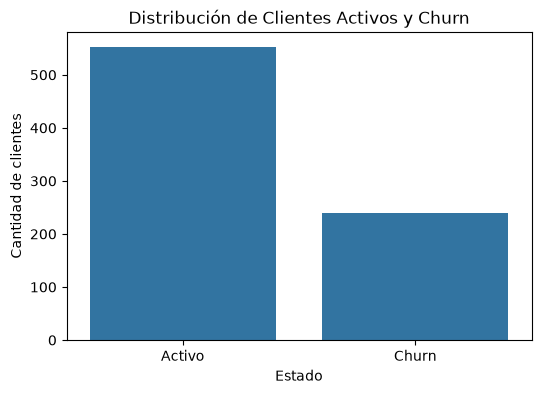

In [8]:
plt.figure(figsize=(6, 4))

sns.countplot(
    data=rfm,
    x="Churn"
)

plt.title("Distribución de Clientes Activos y Churn")
plt.xlabel("Estado")
plt.ylabel("Cantidad de clientes")

plt.xticks(
    [0, 1],
    ["Activo", "Churn"]
)

plt.show()

In [9]:
rfm_features = (
    df_clean.groupby("Customer ID")
    .agg(
        Frequency=("Order ID", "nunique"),
        Monetary_Sum=("Sales", "sum"),
        Monetary_Mean=("Sales", "mean"),
        Monetary_Std=("Sales", "std"),
        Cat_Count=("Category", "nunique"),
        SubCat_Count=("Sub-Category", "nunique")
    )
    .reset_index()
)

In [10]:
rfm_features["Monetary_Std"] = (
    rfm_features["Monetary_Std"].fillna(0)
)

In [11]:
rfm_features = rfm_features.merge(
    rfm[["Customer ID", "Churn"]],
    on="Customer ID",
    how="left"
)

rfm_features.head()

,Customer ID,Frequency,Monetary_Sum,Monetary_Mean,Monetary_Std,Cat_Count,SubCat_Count,Churn
0,AA-10315,5,5563.560,505.778182,1157.990034,3,9,1
1,AA-10375,9,1056.390,70.426000,126.508857,3,7,0
2,AA-10480,4,1790.512,149.209333,176.229194,3,7,1
3,AA-10645,6,5086.935,282.607500,429.222188,3,9,1
4,AB-10015,3,886.156,147.692667,139.432371,3,5,1


In [12]:
X = rfm_features.drop(
    columns=[
        "Customer ID",
        "Churn"
    ]
)

y = rfm_features["Churn"]

print(X.columns)

Index(['Frequency', 'Monetary_Sum', 'Monetary_Mean', 'Monetary_Std',
       'Cat_Count', 'SubCat_Count'],
      dtype='str')


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)

print("\nDistribución entrenamiento:")
print(y_train.value_counts(normalize=True))

print("\nDistribución prueba:")
print(y_test.value_counts(normalize=True))

X_train: (634, 6)
X_test: (159, 6)

Distribución entrenamiento:
Churn
0    0.697161
1    0.302839
Name: proportion, dtype: float64

Distribución prueba:
Churn
0    0.698113
1    0.301887
Name: proportion, dtype: float64


In [15]:
model_rf = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model_rf.fit(
    X_train,
    y_train
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [16]:
y_pred_rf = model_rf.predict(
    X_test
)

y_proba_rf = model_rf.predict_proba(
    X_test
)[:, 1]

In [17]:
accuracy_rf = accuracy_score(
    y_test,
    y_pred_rf
)

precision_rf = precision_score(
    y_test,
    y_pred_rf
)

recall_rf = recall_score(
    y_test,
    y_pred_rf
)

f1_rf = f1_score(
    y_test,
    y_pred_rf
)

roc_auc_rf = roc_auc_score(
    y_test,
    y_proba_rf
)

print("=== RANDOM FOREST BASE ===")

print(f"Accuracy:  {accuracy_rf:.4f}")
print(f"Precision: {precision_rf:.4f}")
print(f"Recall:    {recall_rf:.4f}")
print(f"F1-Score:  {f1_rf:.4f}")
print(f"ROC-AUC:   {roc_auc_rf:.4f}")

print("\nReporte:")
print(
    classification_report(
        y_test,
        y_pred_rf
    )
)

=== RANDOM FOREST BASE ===
Accuracy:  0.7044
Precision: 0.5385
Recall:    0.1458
F1-Score:  0.2295
ROC-AUC:   0.6984

Reporte:
              precision    recall  f1-score   support

           0       0.72      0.95      0.82       111
           1       0.54      0.15      0.23        48

    accuracy                           0.70       159
   macro avg       0.63      0.55      0.52       159
weighted avg       0.66      0.70      0.64       159



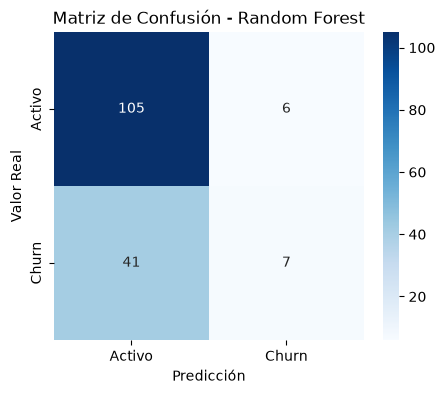

In [18]:
cm_rf = confusion_matrix(
    y_test,
    y_pred_rf
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_rf,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Activo", "Churn"],
    yticklabels=["Activo", "Churn"]
)

plt.title("Matriz de Confusión - Random Forest")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")

plt.show()

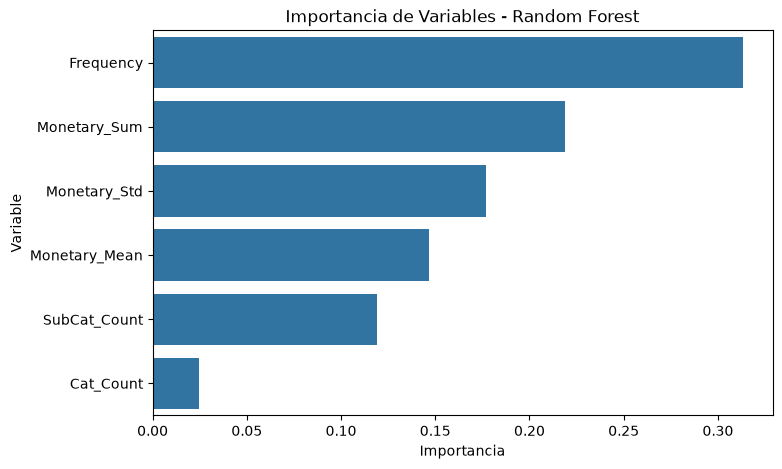

In [19]:
importancias_rf = pd.DataFrame({
    "Variable": X.columns,
    "Importancia": model_rf.feature_importances_
})

importancias_rf = importancias_rf.sort_values(
    by="Importancia",
    ascending=False
)

plt.figure(figsize=(8, 5))

sns.barplot(
    data=importancias_rf,
    x="Importancia",
    y="Variable"
)

plt.title("Importancia de Variables - Random Forest")
plt.xlabel("Importancia")
plt.ylabel("Variable")

plt.show()

In [20]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

param_grid_rf = {
    "n_estimators": [100, 200, 300],
    "max_depth": [3, 5, 10, None],
    "min_samples_split": [2, 5],
    "min_samples_leaf": [1, 2]
}

In [21]:
grid_rf = GridSearchCV(
    estimator=RandomForestClassifier(
        random_state=42
    ),
    param_grid=param_grid_rf,
    scoring="recall",
    cv=cv,
    n_jobs=-1,
    verbose=1
)

grid_rf.fit(
    X_train,
    y_train
)

print("Mejores parámetros:")
print(grid_rf.best_params_)

print("\nMejor Recall en validación cruzada:")
print(grid_rf.best_score_)

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Mejores parámetros:
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 100}

Mejor Recall en validación cruzada:
0.3388663967611336


In [22]:
best_rf = grid_rf.best_estimator_

y_pred_best = best_rf.predict(
    X_test
)

y_proba_best = best_rf.predict_proba(
    X_test
)[:, 1]

In [23]:
accuracy_best = accuracy_score(
    y_test,
    y_pred_best
)

precision_best = precision_score(
    y_test,
    y_pred_best
)

recall_best = recall_score(
    y_test,
    y_pred_best
)

f1_best = f1_score(
    y_test,
    y_pred_best
)

roc_auc_best = roc_auc_score(
    y_test,
    y_proba_best
)

print("=== RANDOM FOREST OPTIMIZADO ===")

print(f"Accuracy:  {accuracy_best:.4f}")
print(f"Precision: {precision_best:.4f}")
print(f"Recall:    {recall_best:.4f}")
print(f"F1-Score:  {f1_best:.4f}")
print(f"ROC-AUC:   {roc_auc_best:.4f}")

=== RANDOM FOREST OPTIMIZADO ===
Accuracy:  0.7233
Precision: 0.5625
Recall:    0.3750
F1-Score:  0.4500
ROC-AUC:   0.6675


In [24]:
smote = SMOTE(
    random_state=42
)

X_train_smote, y_train_smote = smote.fit_resample(
    X_train,
    y_train
)

print("Antes de SMOTE:")
print(y_train.value_counts())

print("\nDespués de SMOTE:")
print(y_train_smote.value_counts())

Antes de SMOTE:
Churn
0    442
1    192
Name: count, dtype: int64

Después de SMOTE:
Churn
0    442
1    442
Name: count, dtype: int64


In [25]:
model_rf_smote = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42
)

model_rf_smote.fit(
    X_train_smote,
    y_train_smote
)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap:

In [26]:
y_pred_smote = model_rf_smote.predict(
    X_test
)

y_proba_smote = model_rf_smote.predict_proba(
    X_test
)[:, 1]

In [27]:
accuracy_smote = accuracy_score(
    y_test,
    y_pred_smote
)

precision_smote = precision_score(
    y_test,
    y_pred_smote
)

recall_smote = recall_score(
    y_test,
    y_pred_smote
)

f1_smote = f1_score(
    y_test,
    y_pred_smote
)

roc_auc_smote = roc_auc_score(
    y_test,
    y_proba_smote
)

print("=== RANDOM FOREST + SMOTE ===")

print(f"Accuracy:  {accuracy_smote:.4f}")
print(f"Precision: {precision_smote:.4f}")
print(f"Recall:    {recall_smote:.4f}")
print(f"F1-Score:  {f1_smote:.4f}")
print(f"ROC-AUC:   {roc_auc_smote:.4f}")

print("\nReporte:")
print(
    classification_report(
        y_test,
        y_pred_smote
    )
)

=== RANDOM FOREST + SMOTE ===
Accuracy:  0.6855
Precision: 0.4861
Recall:    0.7292
F1-Score:  0.5833
ROC-AUC:   0.7173

Reporte:
              precision    recall  f1-score   support

           0       0.85      0.67      0.75       111
           1       0.49      0.73      0.58        48

    accuracy                           0.69       159
   macro avg       0.67      0.70      0.67       159
weighted avg       0.74      0.69      0.70       159



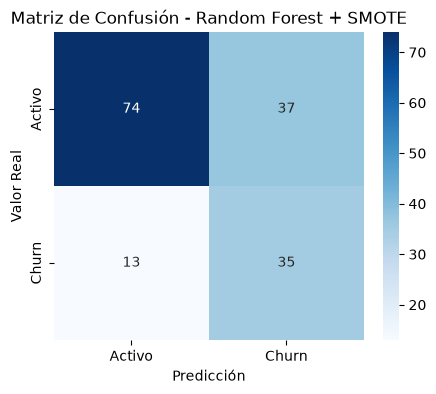

In [28]:
cm_smote = confusion_matrix(
    y_test,
    y_pred_smote
)

plt.figure(figsize=(5, 4))

sns.heatmap(
    cm_smote,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Activo", "Churn"],
    yticklabels=["Activo", "Churn"]
)

plt.title("Matriz de Confusión - Random Forest + SMOTE")
plt.xlabel("Predicción")
plt.ylabel("Valor Real")

plt.show()

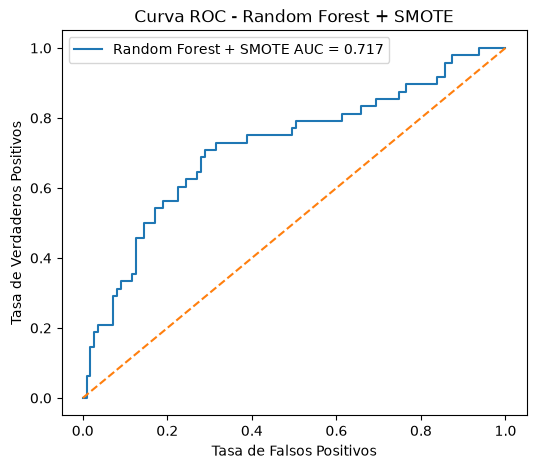

In [29]:
fpr, tpr, thresholds = roc_curve(
    y_test,
    y_proba_smote
)

plt.figure(figsize=(6, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Random Forest + SMOTE AUC = {roc_auc_smote:.3f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--"
)

plt.title("Curva ROC - Random Forest + SMOTE")
plt.xlabel("Tasa de Falsos Positivos")
plt.ylabel("Tasa de Verdaderos Positivos")

plt.legend()
plt.show()

In [30]:
comparacion_rf = pd.DataFrame({
    "Modelo": [
        "Random Forest Base",
        "Random Forest Optimizado",
        "Random Forest + SMOTE"
    ],
    "Accuracy": [
        accuracy_rf,
        accuracy_best,
        accuracy_smote
    ],
    "Precision": [
        precision_rf,
        precision_best,
        precision_smote
    ],
    "Recall": [
        recall_rf,
        recall_best,
        recall_smote
    ],
    "F1-Score": [
        f1_rf,
        f1_best,
        f1_smote
    ],
    "ROC-AUC": [
        roc_auc_rf,
        roc_auc_best,
        roc_auc_smote
    ]
})

comparacion_rf

,Modelo,Accuracy,Precision,Recall,F1-Score,ROC-AUC
0,Random Forest Base,0.704403,0.538462,0.145833,0.229508,0.698386
1,Random Forest Optimizado,0.723270,0.562500,0.375000,0.450000,0.667511
2,Random Forest + SMOTE,0.685535,0.486111,0.729167,0.583333,0.717342


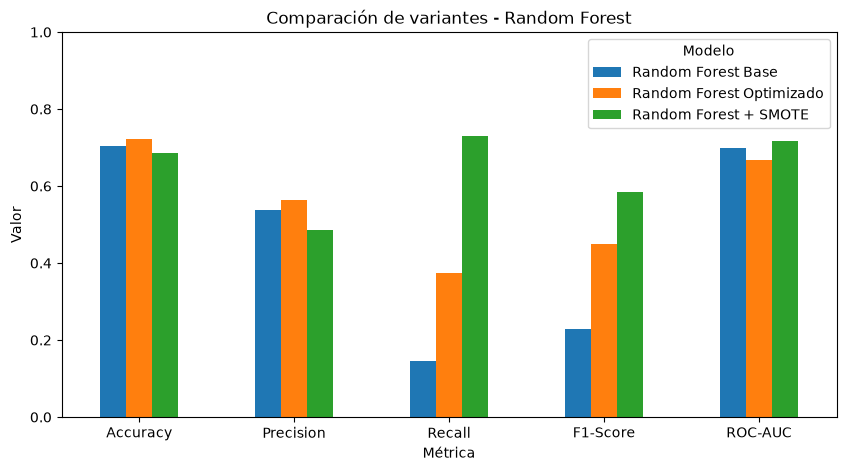

In [31]:
comparacion_plot = (
    comparacion_rf
    .set_index("Modelo")
    .T
)

comparacion_plot.plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylim(0, 1)

plt.title(
    "Comparación de variantes - Random Forest"
)

plt.ylabel("Valor")
plt.xlabel("Métrica")

plt.xticks(rotation=0)

plt.legend(
    title="Modelo"
)

plt.show()

In [32]:
joblib.dump(
    model_rf_smote,
    "modelo_randomforest_smote.pkl"
)

print(
    "Modelo Random Forest + SMOTE guardado correctamente."
)

Modelo Random Forest + SMOTE guardado correctamente.
